<a href="https://colab.research.google.com/github/cathykam2006/Capstone-Project-Illuminado-Retinal--Image-Classification/blob/main/notebooks/01_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
from google.colab import drive
drive.flush_and_unmount()

In [12]:
   !rm -rf /content/repo

# 01 · Data preparation

Builds a **manifest**: one row per image with its split, file path and all 45 disease labels.

**What changed from the original Part 1 and Part 4 notebooks**
- Images are no longer moved into `Yes_disease/`, `No_disease/` or disease folders. Moving files lost labels: an image with both DR and ODC could only live in one folder, and about 150 DR/MH/ODC images ended up in other folders and were silently dropped.
- The manifest keeps every label, so the disease model can be multi-label.
- Each image is cropped to the fundus and shrunk once to 512 px. This turns about 40 GB of PNGs into under 1 GB and makes training on a Colab GPU practical.
- Missing or duplicate images raise an error instead of being skipped silently.

Runtime: about 15 to 25 minutes the first time (mostly caching), seconds after that.

In [3]:
# --- Setup (run once per session) -------------------------------------------
# On Colab: mounts Google Drive, clones this repo and installs requirements.
# Locally: just makes the `iluminado` package importable.
import os, sys, subprocess

REPO_URL = "https://github.com/cathykam2006/Capstone-Project-Illuminado-Retinal--Image-Classification.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

REPO_DIR = next(p for p in [os.getcwd(), os.path.dirname(os.getcwd())] if os.path.isdir(os.path.join(p, "iluminado")))
sys.path.insert(0, REPO_DIR)
print("Repo:", REPO_DIR)

Mounted at /content/drive
Repo: /content/repo


In [4]:
# --- Config: edit these paths ---------------------------------------------------
# PROJECT_DIR holds the cached images, trained models and results. On Colab it
# lives on your Google Drive so it survives between sessions.
PROJECT_DIR = "/content/drive/MyDrive/iluminado" if IN_COLAB else os.path.join(REPO_DIR, "work")
LABEL_DIR = os.path.join(REPO_DIR, "data")            # the three RFMiD label CSVs (in the repo)
MANIFEST = os.path.join(PROJECT_DIR, "manifest.csv")  # written by notebook 01
os.makedirs(PROJECT_DIR, exist_ok=True)

## Get the images

Set `SOURCE` to one of:

- **`"huggingface"` (default, no login).** Downloads the public mirror (about 8 GB) and exports it with its own label files, so every image travels with its labels. Re-running skips images already exported. This route has already worked on your Mac.
- **`"kaggle"`.** Downloads with `kagglehub`; asks for your Kaggle API token on first use. If the dataset name has changed, search Kaggle for "RFMiD" and update `KAGGLE_SLUG`.
- **`"local"`.** You already have the images: set `IMAGE_ROOT` to the folder containing the training, validation and test image folders.

For Kaggle and local copies, the official label CSVs in the repo's `data/` folder are used. The loader finds images by folder name (anything containing *train*, *valid*/*evaluation*, *test*), so any of these layouts works.

In [5]:
SOURCE = "huggingface"            # "huggingface" | "kaggle" | "local"
KAGGLE_SLUG = "andrewmvd/retinal-disease-classification"
IMAGE_ROOT = "/content/drive/MyDrive/RFMiD"   # only used if SOURCE == "local"

if SOURCE == "huggingface":
    from iluminado.download import fetch_hf, compare_with_official
    IMAGE_ROOT, LABEL_DIR_DL = fetch_hf(os.path.join(PROJECT_DIR, "rfmid"), official_dir=LABEL_DIR)
    print("Downloaded labels vs the official CSVs in the repo:")
    display(compare_with_official(LABEL_DIR_DL, LABEL_DIR))
    LABEL_DIR = str(LABEL_DIR_DL)     # use the labels that came with these images
elif SOURCE == "kaggle":
    import kagglehub
    IMAGE_ROOT = kagglehub.dataset_download(KAGGLE_SLUG)
print("Images under:", IMAGE_ROOT, "| labels from:", LABEL_DIR)

Loading bumbledeep/rfmid from the Hugging Face Hub (first run downloads about 8 GB) ...


README.md:   0%|          | 0.00/9.43k [00:00<?, ?B/s]

data/train-00000-of-00007.parquet: reconstructing file:   0%|          |  0.00B /  477MB            

data/train-00000-of-00007.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00007.parquet: reconstructing file:   0%|          |  0.00B /  473MB            

...

Generating validation split:   0%|          | 0/640 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/640 [00:00<?, ? examples/s]

Exporting train: 1920 images
Exporting validation: 640 images
Exporting test: 640 images
Downloaded labels vs the official CSVs in the repo:


,images,official,column totals match,identical rows (same ID)
split,,,,
train,1920,1920,True,1.0
val,640,640,True,1.0
test,640,640,True,1.0


Images under: /content/drive/MyDrive/iluminado/rfmid/images | labels from: /content/drive/MyDrive/iluminado/rfmid/labels


If **column totals match** for every split, the label counts agree with the official release. *Identical rows* below 1.0 would only mean the mirror numbers images in a different order from the official IDs, which is harmless here because each image keeps its own labels.

## Build and check the manifest

In [6]:
import pandas as pd
from iluminado.data import build_manifest, TARGET_DISEASES

manifest = build_manifest(IMAGE_ROOT, LABEL_DIR)

expected = {"train": 1920, "val": 640, "test": 640}
counts = manifest["split"].value_counts().to_dict()
assert counts == expected, f"Unexpected split sizes: {counts}"
print("All 3,200 labelled images found:", counts)
manifest.head()

All 3,200 labelled images found: {'train': 1920, 'val': 640, 'test': 640}


,split,ID,Disease_Risk,DR,ARMD,MH,DN,MYA,BRVO,TSLN,...,PTCR,CF,VH,MCA,VS,BRAO,PLQ,HPED,CL,path
0,train,1,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,/content/drive/MyDrive/iluminado/rfmid/images/...
1,train,2,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,/content/drive/MyDrive/iluminado/rfmid/images/...
2,train,3,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,/content/drive/MyDrive/iluminado/rfmid/images/...
3,train,4,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,/content/drive/MyDrive/iluminado/rfmid/images/...
4,train,5,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,/content/drive/MyDrive/iluminado/rfmid/images/...


In [7]:
# Original image size = best available clue to which of the three cameras took each photo (used by the EDA camera check)
from PIL import Image
info_csv = os.path.join(str(LABEL_DIR), "image_info.csv")
if SOURCE == "huggingface" and os.path.exists(info_csv):
    sizes = pd.read_csv(info_csv)          # recorded before the export shrank the images
else:
    def _size(p):
        with Image.open(p) as im:
            return im.size
    wh = manifest["path"].map(_size)
    sizes = manifest[["split", "ID"]].assign(orig_w=[w for w, _ in wh], orig_h=[h for _, h in wh])
sizes.to_csv(os.path.join(PROJECT_DIR, "image_sizes.csv"), index=False)
sizes.groupby(["orig_w", "orig_h"]).size().rename("images").to_frame()

,,images
orig_w,orig_h,
2048,1536,276
2144,1424,2427
4288,2848,497


## Why multi-label

How many images carry more than one of the three target diseases, and how many target-disease images would the old folder approach have dropped?

In [8]:
t = manifest[TARGET_DISEASES]
summary = pd.DataFrame({
    "images with DR/MH/ODC": manifest.assign(k=t.sum(axis=1)).query("k >= 1").groupby("split").size(),
    "with 2+ of them": manifest.assign(k=t.sum(axis=1)).query("k >= 2").groupby("split").size(),
    "with any 2+ diseases": manifest.assign(k=manifest.drop(columns=["split", "ID", "path", "Disease_Risk"]).sum(axis=1)).query("k >= 2").groupby("split").size(),
})
summary

,images with DR/MH/ODC,with 2+ of them,with any 2+ diseases
split,,,
test,276,42,139
train,874,99,458
val,267,39,152


## Crop and cache

In [9]:
from iluminado.data import cache_images

CACHE_SIZE = 512   # training uses 384 by default; caching a bit larger leaves room to experiment
manifest_raw_path = os.path.join(PROJECT_DIR, "manifest_raw.csv")
manifest.to_csv(manifest_raw_path, index=False)   # original paths, used by the EDA notebook

cached = cache_images(manifest, os.path.join(PROJECT_DIR, f"cache_{CACHE_SIZE}"), size=CACHE_SIZE)
cached.to_csv(MANIFEST, index=False)
print("Saved", MANIFEST, len(cached), "rows")

Saved /content/drive/MyDrive/iluminado/manifest.csv 3200 rows


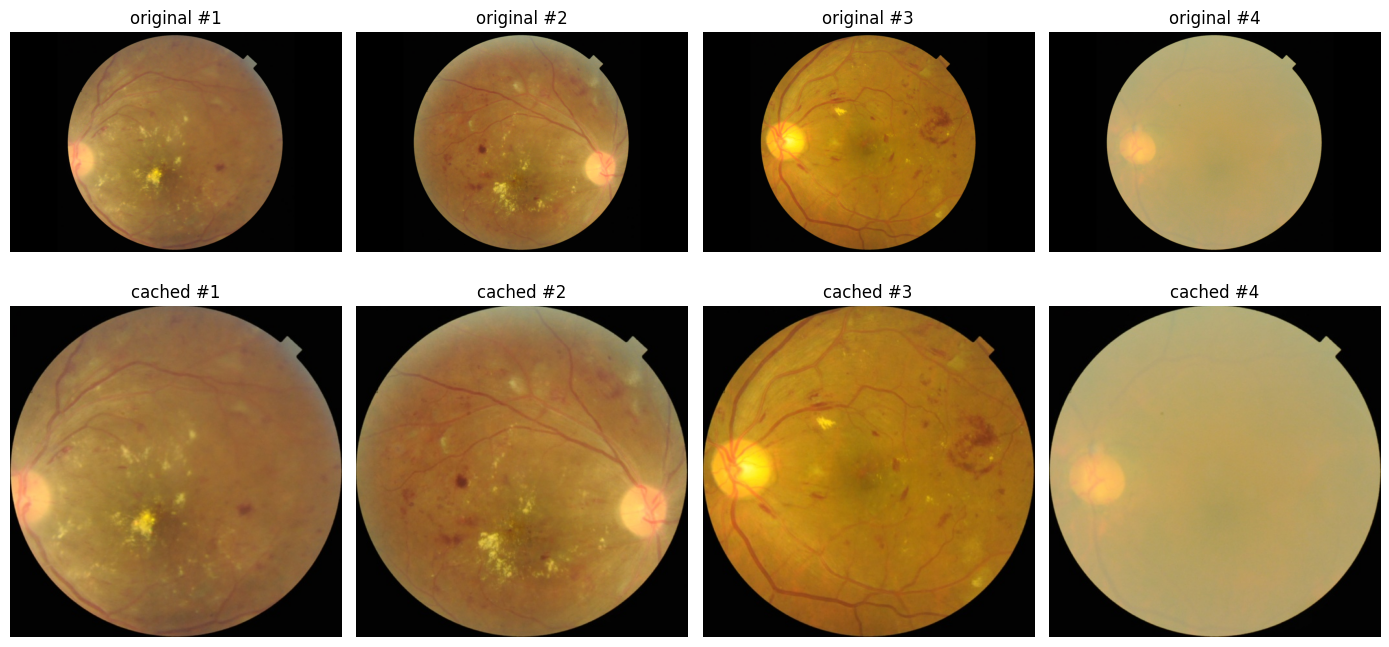

In [10]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, row) in zip(axes[1], cached.head(4).iterrows()):
    ax.imshow(Image.open(row.path)); ax.set_title(f"cached #{row.ID}"); ax.axis("off")
for ax, (_, raw) in zip(axes[0], manifest.head(4).iterrows()):
    ax.imshow(Image.open(raw.path)); ax.set_title(f"original #{raw.ID}"); ax.axis("off")
plt.tight_layout(); plt.show()